Model Accuracy: 0.956


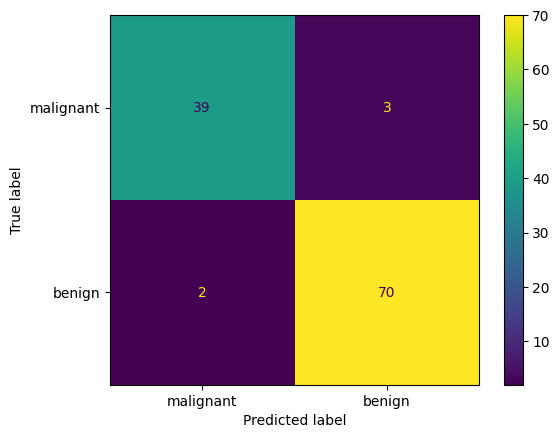

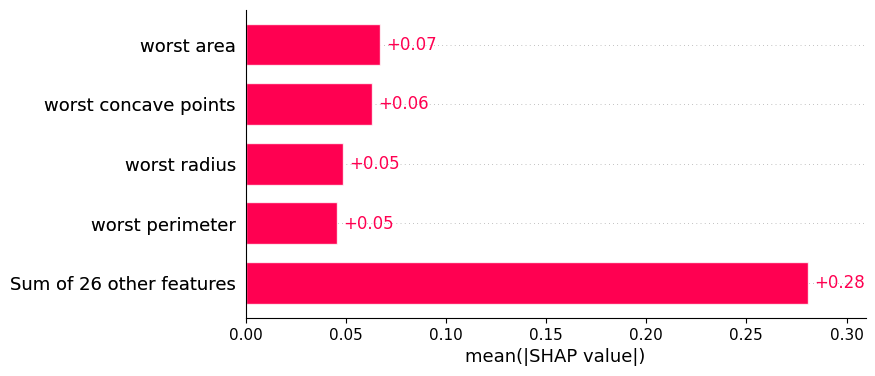

Actual: malignant
Predicted: malignant


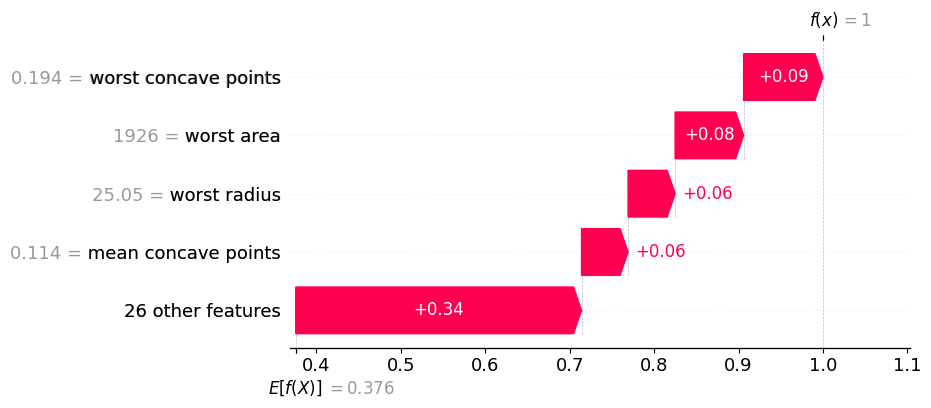

In [3]:
!pip -q install shap

import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 1. Load Dataset
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

# 2. Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Train Model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, pred), 3))

# 4. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=data.target_names
)
plt.show()

# 5. SHAP Explanations
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

# Explain malignant class
malignant_index = list(data.target_names).index("malignant")
malignant_values = shap_values[:, :, malignant_index]

# 6. Top 5 Important Features
shap.plots.bar(malignant_values, max_display=5)

# 7. Explain One Prediction
i = 0
print("Actual:", data.target_names[y_test.iloc[i]])
print("Predicted:", data.target_names[pred[i]])

shap.plots.waterfall(malignant_values[i], max_display=5)
